# Exercice 1 — Les blocs de construction de l'Apprentissage par Renforcement

**Objectif** : interagir pour la première fois avec un environnement RL et comprendre le cycle fondamental

```
            action aₜ
   Agent ───────────────▶ Environnement
     ▲                         │
     └──── observation sₜ₊₁, récompense rₜ₊₁ ◀┘
```

Environnement utilisé : **CartPole-v1** (Gymnasium). Un chariot doit maintenir un bâton en équilibre ;
chaque pas de temps où le bâton reste debout rapporte **+1**. L'épisode se termine si le bâton tombe
(> 12°), si le chariot sort de la piste (|x| > 2.4), ou après 500 pas (troncature).

Plan :
1. Créer l'environnement et explorer ses espaces d'observation et d'action.
2. Faire jouer un agent **aléatoire** pendant 10 épisodes et afficher la récompense totale de chacun.

In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

print("Gymnasium", gym.__version__)

Gymnasium 1.4.0


## Étape 1 — Créer l'environnement et explorer ses espaces

- `observation_space` : ce que l'agent **voit**.
- `action_space` : ce que l'agent **peut faire**.

In [2]:
env = gym.make("CartPole-v1")

print("Espace d'observation :", env.observation_space)
print("  type   :", type(env.observation_space).__name__)
print("  shape  :", env.observation_space.shape)
print("  low    :", env.observation_space.low)
print("  high   :", env.observation_space.high)
print()
print("Espace d'action :", env.action_space)
print("  type   :", type(env.action_space).__name__)
print("  n      :", env.action_space.n)

Espace d'observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
  type   : Box
  shape  : (4,)
  low    : [-4.8               -inf -0.41887903        -inf]
  high   : [4.8               inf 0.41887903        inf]

Espace d'action : Discrete(2)
  type   : Discrete
  n      : 2


### Lecture des espaces

| Index | Observation (Box, continu)  | Bornes          |
|------:|-----------------------------|-----------------|
| 0     | Position du chariot         | ±4.8            |
| 1     | Vitesse du chariot          | ±∞              |
| 2     | Angle du bâton (rad)        | ±0.418 (≈ 24°)  |
| 3     | Vitesse angulaire du bâton  | ±∞              |

| Action (Discrete(2)) | Effet                      |
|---------------------:|----------------------------|
| 0                    | Pousser le chariot à gauche |
| 1                    | Pousser le chariot à droite |

⚠️ **Point de vigilance** : l'observation est **continue** (`Box`) alors que l'action est **discrète** (`Discrete`).
Cette distinction est cruciale : un espace d'états continu ne peut pas être stocké dans une Q-table
(exercice 2) → il faudra un réseau de neurones (DQN, exercice 3).

In [3]:
# Exemples tirés au hasard dans chaque espace avec .sample()
for i in range(3):
    print(f"Observation aléatoire {i}: {env.observation_space.sample()}")
for i in range(5):
    print(f"Action aléatoire {i}: {env.action_space.sample()}")

Observation aléatoire 0: [-4.3146253  -1.0511854  -0.18085097  0.6760662 ]
Observation aléatoire 1: [-4.382744   -1.5354625  -0.11015008 -0.5370177 ]
Observation aléatoire 2: [-4.5983243   0.5957712  -0.12437414 -0.71595913]
Action aléatoire 0: 0
Action aléatoire 1: 1
Action aléatoire 2: 0
Action aléatoire 3: 0
Action aléatoire 4: 0


### Un pas dans l'environnement

`env.reset()` renvoie `(observation, info)` ; `env.step(action)` renvoie **5 valeurs** :
`observation, reward, terminated, truncated, info`.

- `terminated` : fin « naturelle » (le bâton tombe, le chariot sort).
- `truncated` : fin artificielle (limite de 500 pas atteinte).

In [4]:
observation, info = env.reset(seed=42)
print("Observation initiale :", observation)

action = env.action_space.sample()
observation, reward, terminated, truncated, info = env.step(action)
print(f"Action jouée : {action}")
print(f"Nouvelle observation : {observation}")
print(f"Récompense : {reward} | terminated={terminated} | truncated={truncated} | info={info}")

Observation initiale : [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Action jouée : 0
Nouvelle observation : [ 0.02727336 -0.20172954  0.03625453  0.32351476]
Récompense : 1.0 | terminated=False | truncated=False | info={}


## Étape 2 — Boucle d'interaction avec un agent aléatoire (10 épisodes)

Pour chaque épisode : `reset()`, puis on joue des actions aléatoires jusqu'à `terminated` **ou** `truncated`,
en cumulant la récompense. Les variables d'épisode sont **réinitialisées** au début de chaque épisode.

In [5]:
N_EPISODES = 10
episode_rewards = []
env.action_space.seed(42)   # tirages d'actions reproductibles

for episode in range(N_EPISODES):
    observation, info = env.reset(seed=episode)
    total_reward = 0.0          # réinitialisation à chaque épisode
    terminated = truncated = False
    steps = 0

    while not (terminated or truncated):
        action = env.action_space.sample()                      # politique aléatoire
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        steps += 1

    episode_rewards.append(total_reward)
    print(f"Épisode {episode + 1:2d} | pas = {steps:3d} | récompense totale = {total_reward:.0f}")

env.close()
print(f"\nMoyenne : {np.mean(episode_rewards):.1f} ± {np.std(episode_rewards):.1f} (max possible : 500)")

Épisode  1 | pas =  20 | récompense totale = 20
Épisode  2 | pas =  22 | récompense totale = 22
Épisode  3 | pas =  37 | récompense totale = 37
Épisode  4 | pas =  20 | récompense totale = 20
Épisode  5 | pas =  28 | récompense totale = 28
Épisode  6 | pas =  10 | récompense totale = 10
Épisode  7 | pas =  13 | récompense totale = 13
Épisode  8 | pas =  45 | récompense totale = 45
Épisode  9 | pas =  13 | récompense totale = 13
Épisode 10 | pas =  19 | récompense totale = 19

Moyenne : 22.7 ± 10.5 (max possible : 500)


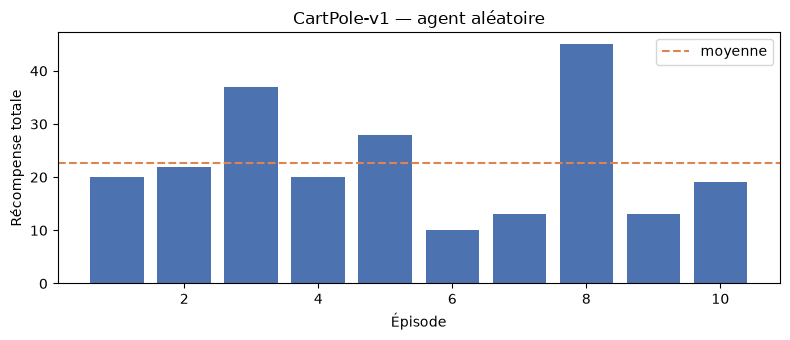

In [6]:
plt.figure(figsize=(8, 3.5))
plt.bar(range(1, N_EPISODES + 1), episode_rewards, color="#4C72B0")
plt.axhline(np.mean(episode_rewards), color="#DD8452", ls="--", label="moyenne")
plt.xlabel("Épisode"); plt.ylabel("Récompense totale")
plt.title("CartPole-v1 — agent aléatoire")
plt.legend(); plt.tight_layout(); plt.show()

## Aperçu visuel

Les fonctions d'aperçu sont regroupées dans [`rl_viz.py`](rl_viz.py) ; les fichiers produits sont enregistrés dans `media/`.

**Animation d'un épisode aléatoire** : le bâton tombe en quelques dizaines de pas.

Épisode aléatoire : 18 pas


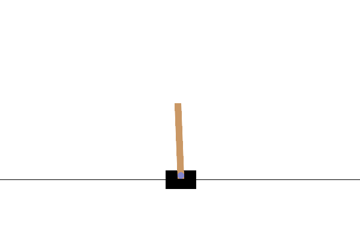

In [7]:
from rl_viz import rollout, save_gif, trajectories_3d

env_vis = gym.make("CartPole-v1", render_mode="rgb_array")
env_vis.action_space.seed(0)
random_policy = lambda obs: env_vis.action_space.sample()

total, states, frames = rollout(env_vis, random_policy, seed=0, render=True)
print(f"Épisode aléatoire : {total:.0f} pas")
save_gif(frames, "ex1_cartpole_aleatoire.gif", fps=15)

**Trajectoires 3D dans l'espace d'état** (graphique interactif : faites-le pivoter à la souris).
Chaque courbe est un épisode, de l'état initial (près de l'origine) jusqu'à la chute (✕).
Les trajectoires s'échappent rapidement le long de l'axe de l'angle : l'agent aléatoire ne corrige rien.

In [8]:
runs = [(f"épisode {i + 1}", rollout(env_vis, random_policy, seed=i)[1]) for i in range(10)]
env_vis.close()
trajectories_3d(runs, "ex1_trajectoires_3d", "CartPole — agent aléatoire : 10 trajectoires",
                labels=("Position x", "Angle θ (rad)", "Vitesse angulaire θ̇"))

## Conclusion

- L'agent aléatoire tient en moyenne **environ 25 pas** (22,7 ± 10,5 ici, très loin des 500 possibles) : il n'apprend rien, il ne fait que subir l'environnement.
- On a mis en place la boucle **observation → action → récompense** qui sera réutilisée partout ensuite.
- Prochaine étape : un agent qui **apprend** de ses récompenses (Q-learning, exercice 2).